In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
import pandas as pd
import pickle
import time
import os
import matplotlib

tau= 24 mean= 7.822404266132657e-07 std= 7.597787673653293e-08
a= 106 b= 135508104.0


C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


tau= 30 mean= 6.101933788449739e-07 std= 5.5936318118970384e-08
a= 119 b= 195020024.0


C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


tau= 40 mean= 4.4219354002664495e-07 std= 4.635446792918087e-08
a= 91 b= 205792151.0


C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


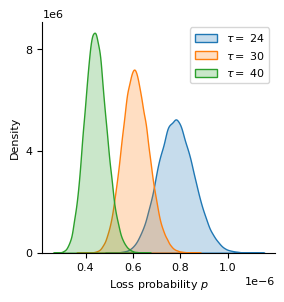

In [3]:
alpha = 1
beta = 1
tau_vec = [24,30,40]

fig = plt.figure(figsize=(3,3))
plt.rc('font', size=8)
ax = fig.add_subplot(111)
means_p = np.zeros(3)
std_p = np.zeros(3)
kk=0

a_vec=np.zeros(3)
b_vec=np.zeros(3)
for tau in tau_vec:
    filename = './loss_vs_division_data/loss/tau'+str(tau)+'.csv'
    loss = pd.read_csv(filename).values
    obs = 1./loss
    n = len(obs)
    sum_obs = np.sum(obs)-n 
    a = alpha+n
    b= beta+sum_obs
    a_vec[kk] = a
    b_vec[kk] = b
    
    mean=a/(a+b)
    std=np.sqrt(a*b/((a+b+1)*(a+b)**2))
    means_p[kk] =mean
    std_p[kk] =std
    samp = np.random.beta(a,b,100000)
    print('tau=',tau,'mean=',mean,'std=',std)
    print('a=',a,'b=',b)
    sns.kdeplot(samp,ax=ax,fill='True',label=r'$\tau=$ %d' %(tau))
    ax.set_xlabel(r'Loss probability $p$')
    ax.set_yticks([0,4e6,8e6])
    ax.set_xticks([0.4e-6,0.6e-6,0.8e-6,1e-6])
    sns.despine()
    kk+=1
plt.legend()

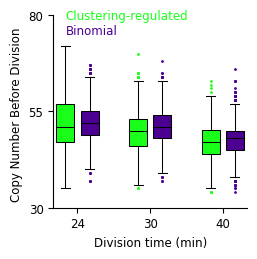

In [7]:
f= plt.figure(figsize=(2.5,2.5))
ax = f.add_subplot(111)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

fontsiz=8.5
plt.rc('font', size=fontsiz)
tau_vec = [24,30,40]

def box_plot(data, edge_color, fill_color,pos,out_color):
    bp = ax.boxplot(data, patch_artist=True,positions=pos,showfliers=True,widths=0.75,sym=out_color)
    for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp[element], color=edge_color, linewidth=0.75)
    for patch in bp['boxes']:
        patch.set(facecolor=fill_color)       
    plt.setp(bp['fliers'], color=edge_color, linewidth=0.25,markersize=1)


tags = [24,30,40]
col = ["#1AFF1A","#4B0092"]

#binomial segregation
tau_vec = [24,30,40]
cp = np.zeros([5000,3])
cp_clust = np.zeros([1000,3])
i=0
for tau in tau_vec:
    filename = './binomial_seg/copy_number_tau_'+str(tau)+'.csv'
    data = np.ndarray.flatten(pd.read_csv(filename).values).astype(int)
    cp[:,i] = data
    
    filename = './clust_reg/tau'+str(tau)+'.csv'
    data = np.ndarray.flatten(pd.read_csv(filename).values).astype(int)
    cp_clust[:,i] = data
    i+=1

box_plot(cp_clust[:,0], 'k', col[0],[1], col[0])
box_plot(cp[:,0], 'k', col[1],[2], col[1])
box_plot(cp_clust[:,1], 'k', col[0],[4], col[0])
box_plot(cp[:,1], 'k', col[1],[5], col[1])
box_plot(cp_clust[:,2], 'k', col[0],[7], col[0])
box_plot(cp[:,2], 'k', col[1],[8], col[1])

   
ax.set_ylim([30,80])
ax.set_yticks([30,55,80])
ax.set_yticklabels([30,55,80],fontsize=fontsiz)
ax.set_xticks([1.5,4.5,7.5])
ax.set_xticklabels(tags,fontsize=fontsiz)
ax.set_xlabel('Division time (min)',fontsize=fontsiz)
ax.set_ylabel('Copy Number Before Division ',fontsize=fontsiz)
sns.despine()
ax.text(1,79,'Clustering-regulated',color=col[0],fontsize=fontsiz)
ax.text(1,75,'Binomial',color=col[1],fontsize=fontsiz)
plt.savefig("copy_number.pdf", format="pdf", bbox_inches="tight")

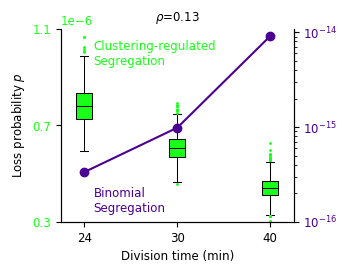

In [8]:
f= plt.figure(figsize=(3,2.5))
ax = f.add_subplot(111)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

fontsiz=8.5
tau_vec = [24,30,40]

def box_plot(data, edge_color, fill_color,pos,out_color):
    bp = ax.boxplot(data, patch_artist=True,positions=pos,showfliers=True,widths=0.35,sym=out_color)
    for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp[element], color=edge_color, linewidth=0.75)
    for patch in bp['boxes']:
        patch.set(facecolor=fill_color)       
    plt.setp(bp['fliers'], color=edge_color, linewidth=0.25,markersize=1)
    return bp

def box_plot2(data, edge_color, fill_color,pos,out_color):
    bp = ax2.boxplot(data, patch_artist=True,positions=pos,showfliers=True,widths=0.35,sym=out_color)
    for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp[element], color=edge_color, linewidth=0.75)
    for patch in bp['boxes']:
        patch.set(facecolor=fill_color)       
    plt.setp(bp['fliers'], color=edge_color, linewidth=0.25,markersize=1)
    return bp

tags = [24,30,40]
col = ["#1AFF1A","#4B0092"]

#impeded segregation
clust_model1 = box_plot(np.random.beta(a_vec[0],b_vec[0],1000), 'k', col[0],[1], col[0])
clust_model2 = box_plot(np.random.beta(a_vec[1],b_vec[1],1000),'k', col[0],[3], col[0])
clust_model3 = box_plot(np.random.beta(a_vec[2],b_vec[2],1000), 'k', col[0],[5], col[0])
ax.spines[['top']].set_visible(False)
ax.set_yticks([3e-7,7e-7,11e-7])
ax.set_ylim([3e-7,11e-7])
ax.tick_params(axis='y', labelcolor=col[0])
ax.set_xticks([1,3,5])
ax.set_xticklabels(tags,fontsize=fontsiz)
ax.set_xlabel('Division time (min)',fontsize=fontsiz)
ax.set_ylabel(r'Loss probability $p$',fontsize=fontsiz)
ax.text(1.2,9.5e-7,'Clustering-regulated\nSegregation',color=col[0],fontsize=fontsiz)
ax.text(1.2,3.4e-7,'Binomial\nSegregation',color=col[1],fontsize=fontsiz)
ax.set_title(r'$\rho$=0.13',fontsize=fontsiz)
#binomial segregation
tau_vec = [24,30,40]
binom_mean = np.zeros(3)
binom_std = np.zeros(3)
i=0

ax2= ax.twinx()
ax2.set_yscale('log')
ax2.plot([1,3,5],np.power(0.5,np.mean(cp,axis=0)-1),'-o',color=col[1])
ax2.set_yticks([1e-16,1e-15,1e-14])
ax2.spines[['top']].set_visible(False)
ax2.tick_params(axis='y', labelcolor=col[1])
ax2.set_xticks([1,3,5])
ax2.set_xticklabels([24,30,40])   
plt.savefig("growth_rates.pdf", format="pdf", bbox_inches="tight")

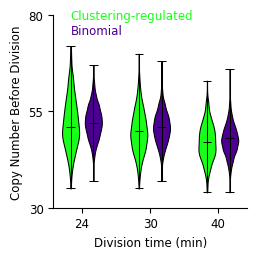

In [4]:
f = plt.figure(figsize=(2.5, 2.5))
ax = f.add_subplot(111)

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
fontsiz = 8.5
plt.rc('font', size=fontsiz)

def violin_plot(data, edge_color, fill_color, pos):
    vp = ax.violinplot(
        data,
        positions=pos,
        widths=0.75,
        showmeans=False,
        showmedians=True,
        showextrema=True
    )

    for body in vp['bodies']:
        body.set_facecolor(fill_color)
        body.set_edgecolor(edge_color)
        body.set_linewidth(0.75)
        body.set_alpha(1)

    for part in ['cbars', 'cmins', 'cmaxes', 'cmedians']:
        vp[part].set_edgecolor(edge_color)
        vp[part].set_linewidth(0.75)

tau_vec = [24, 30, 40]
cp = np.zeros([5000, 3])
cp_clust = np.zeros([1000, 3])

for i, tau in enumerate(tau_vec):

    filename = './loss_vs_division_data/binomial_seg/copy_number_tau_' + str(tau) + '.csv'
    data = np.ndarray.flatten(pd.read_csv(filename).values).astype(int)
    cp[:, i] = data

    filename = './loss_vs_division_data/clust_reg/tau' + str(tau) + '.csv'
    data = np.ndarray.flatten(pd.read_csv(filename).values).astype(int)
    cp_clust[:, i] = data


col = ["#1AFF1A", "#4B0092"]

violin_plot(cp_clust[:, 0], 'k', col[0], [1])
violin_plot(cp[:, 0], 'k', col[1], [2])

violin_plot(cp_clust[:, 1], 'k', col[0], [4])
violin_plot(cp[:, 1], 'k', col[1], [5])

violin_plot(cp_clust[:, 2], 'k', col[0], [7])
violin_plot(cp[:, 2], 'k', col[1], [8])

tags = [24, 30, 40]
ax.set_ylim([30, 80])
ax.set_yticks([30, 55, 80])
ax.set_yticklabels([30, 55, 80], fontsize=fontsiz)
ax.set_xticks([1.5, 4.5, 7.5])
ax.set_xticklabels(tags, fontsize=fontsiz)
ax.set_xlabel('Division time (min)', fontsize=fontsiz)
ax.set_ylabel('Copy Number Before Division', fontsize=fontsiz)
ax.text(1, 79, 'Clustering-regulated', color=col[0], fontsize=fontsiz)
ax.text(1, 75, 'Binomial', color=col[1], fontsize=fontsiz)
sns.despine()
plt.savefig("copy_number.pdf", format="pdf", bbox_inches="tight")

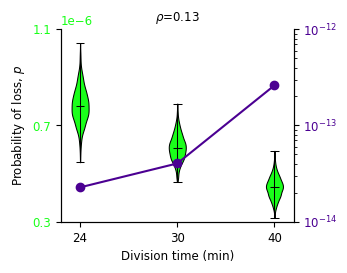

In [26]:
f = plt.figure(figsize=(3, 2.5))
ax = f.add_subplot(111)

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
fontsiz = 8.5
plt.rc('font', size=fontsiz)

tags = [24, 30, 40]
col = ["#1AFF1A", "#4B0092"]

def violin_box(ax_handle, data, edge_color, fill_color, pos, width=0.35):
    vp = ax_handle.violinplot(data,positions=pos,widths=width,showmeans=False,showmedians=True,showextrema=True)

    for body in vp['bodies']:
        body.set_facecolor(fill_color)
        body.set_edgecolor(edge_color)
        body.set_linewidth(0.75)
        body.set_alpha(1)

    for part in ['cbars', 'cmins', 'cmaxes', 'cmedians']:
        vp[part].set_edgecolor(edge_color)
        vp[part].set_linewidth(0.75)

violin_box(ax, np.random.beta(a_vec[0], b_vec[0], 1000), 'k', col[0], [1])
violin_box(ax, np.random.beta(a_vec[1], b_vec[1], 1000), 'k', col[0], [3])
violin_box(ax, np.random.beta(a_vec[2], b_vec[2], 1000), 'k', col[0], [5])

ax.spines[['top']].set_visible(False)
ax.set_ylim([3e-7, 11e-7])
ax.set_yticks([3e-7, 7e-7, 11e-7])
ax.tick_params(axis='y', labelcolor=col[0])
ax.set_xticks([1, 3, 5])
ax.set_xticklabels(tags, fontsize=fontsiz)
ax.set_xlabel('Division time (min)', fontsize=fontsiz)
ax.set_ylabel(r'Probability of loss, $p$', fontsize=fontsiz)
ax.set_title(r'$\rho$=0.13', fontsize=fontsiz)

ax2 = ax.twinx()
ax2.set_yscale('log')
cp_binom = np.power(0.5, cp - 1)
p_binom_mean = np.mean(cp_binom, axis=0)
ax2.plot([1, 3, 5],p_binom_mean,'-o',color=col[1])

ax2.set_yticks([1e-14, 1e-13, 1e-12])
ax2.spines[['top']].set_visible(False)
ax2.tick_params(axis='y', labelcolor=col[1])
ax2.set_xticks([1, 3, 5])
ax2.set_xticklabels(tags)
plt.savefig("growth_rates.pdf", format="pdf", bbox_inches="tight")